# PCA en el dataset Iris usando SVD

Empezaremos implementando el método PCA desde cero (sin usar librerías) en el dataset de iris tomando únicamente las dos últimas componentes.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris


In [ ]:
# Cargamos el dataset
data_iris = load_iris()

# Convertir el conjunto de datos de iris en un DataFrame de pandas
df = pd.DataFrame(data_iris.data, columns=data_iris.feature_names)

# Añadimos la variable objetivo al DataFrame
df['target'] = data_iris.target

# Visualizamos
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [ ]:
data_iris.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

Vamos a llevar a cabo un análisis utilizando únicamente dos variables para una mejor visualización

In [ ]:
# Tomamos las dos últimas compoentes
X_iris = ___
y_iris = ___

# De cara a las representaciones gráficas, vamos a separar las coordendas de las
# dos variables en dos vectores distintos
x1 = ___
x2 = ___

clases = np.unique(y_iris)
clases

array([0, 1, 2])

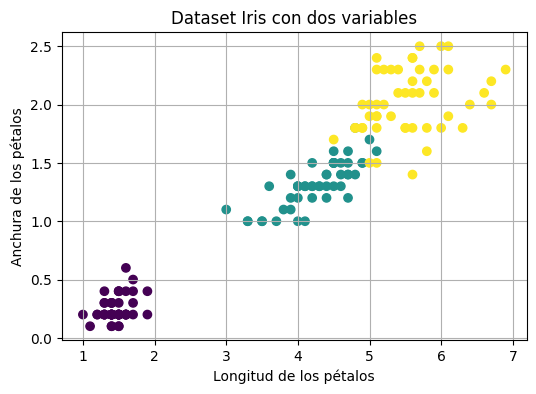

In [ ]:
# Representamos los datos
plt.figure(figsize=(6, 4))

#Incluir las etiquetas de las clases
plt.scatter(___, ___, c=y_iris, cmap='viridis')
plt.___('Longitud de los pétalos')
plt.___('Anchura de los pétalos')
plt.title('Dataset Iris con dos variables')
plt.grid(True)
plt.show()

## 2. Aplicamos el método de la descomposición en valores singulares (SVD)





En primer lugar centramos los datos:

\

$$
X =
\begin{pmatrix}
  x'_{11} - \overline{x'_1}     & x'_{12} - \overline{x'_2}   & \cdots  & x'_{1p} - \overline{x'}_p  \\
  x'_{21} - \overline{x'_1}    & x'_{22}  - \overline{x'_2} & \ddots  &  \vdots \\
  \vdots     & \ddots   & \ddots  & \vdots  \\
  \vdots     & \ddots   & \ddots  & \vdots  \\
  x'_{N1} - \overline{x'_1}     & \cdots   & \cdots  & x'_{Np} - \overline{x'}_p
\end{pmatrix}
$$
\
Donde los valores $x'_{ij}$ representan las componentes de las observaciones originales.

In [ ]:
# Centramos los datos restando la media
X_centered = ___

x1_centered = ___
x2_centered = ___


In [ ]:
X_centered.___

(150, 2)

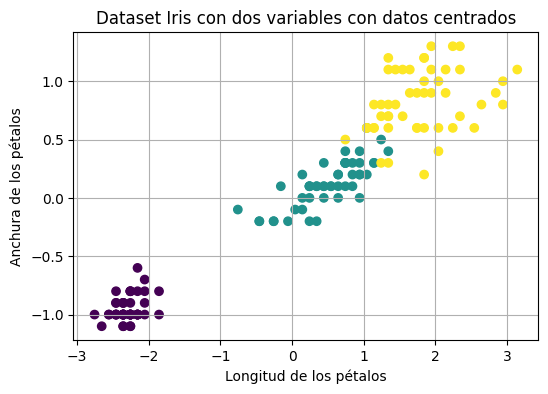

In [ ]:
# Representamos los datos
plt.figure(figsize=(6, 4))

#Incluir las etiquetas de las clases
plt.scatter(___, ___, c=y_iris, cmap='viridis')
plt.___('Longitud de los pétalos')
plt.___('Anchura de los pétalos')
plt.title('Dataset Iris con dos variables con datos centrados')
plt.grid(True)
plt.show()

Calculemos la varianza de los datos a lo largo de la primera variable
$\mathbf{x_1}$:



\

$$
\mathbf{x_1} = \begin{pmatrix}
    x_{11} \\
    x_{12} \\
    \vdots \\
    x_{1N}
\end{pmatrix}
$$

In [ ]:
x1 = ___
np.var(x1,ddof=1)

3.116277852348994

Lo mismo para la segunda: $\mathbf{x_2}$

In [ ]:
x2 = ___
np.var(x2,ddof=1)

0.5810062639821031

Nótese que los resultados son coherentes con la representación de los datos obtenida anteriormente. Lo que nos interesa ahora es encontrar la dirección a lo largo de la cual esa varianza sea máxima.

In [ ]:
N = X_centered.shape[___]
Q = ___
print(Q)

[[3.11627785 1.2956094 ]
 [1.2956094  0.58100626]]


## Aplicamos la descomposición en valores singulares con las observaciones centradas:


$$
X = U \Sigma V^T
$$

In [ ]:
# Utilizamos la función linalg.svd de numpy
U, s, Vt = ___

#Trasponemos Vt para obtener V
V = Vt.T
V

array([[ 0.92177769, -0.38771882],
       [ 0.38771882,  0.92177769]])

La matriz V contiene las siguientes componentes principales

$$
V =
\begin{pmatrix}
    \vert & \vert & \vert & \vert \\
    \mathbf{v_1}   & \mathbf{v_2} & \cdots & \mathbf{v_p} \\
    \vert & \vert & \vert & \vert
\end{pmatrix}
$$

In [ ]:
#La primera componente principal v1 es
___

array([0.92177769, 0.38771882])

In [ ]:
#La segunda componente principal v2 es
___

array([-0.38771882,  0.92177769])

De acuerdo a la teoría, $\mathbf{v1}$ nos proporciona dicha dirección a lo largo de la cual la varianza de los datos es máxima.

Veamos ahora los datos expresados en la nueva base: $\mathbf{v_1},\mathbf{v_2},...,\mathbf{v_N}$

In [ ]:
Z = X_centered @ V

z1 = ___
z2 = ___

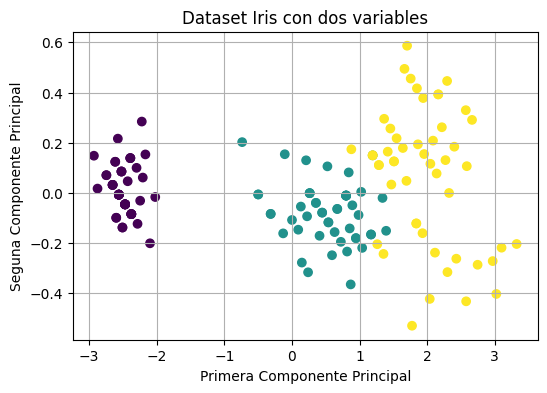

In [ ]:
# Representamos los datos
plt.figure(figsize=(6, 4))

#Incluir las etiquetas de las clases
plt.scatter(z1, z2, c=y_iris, cmap='viridis')
plt.___('Primera Componente Principal')
plt.___('Seguna Componente Principal')
plt.title('Dataset Iris con dos variables')
plt.grid(True)
plt.show()

Así, pues vamos a proyectar las observaciones centradas sobre la primera componente principal:

## Representamos la primera componente principal sobre base original

In [ ]:
#Recordamos V
V

array([[ 0.92177769, -0.38771882],
       [ 0.38771882,  0.92177769]])

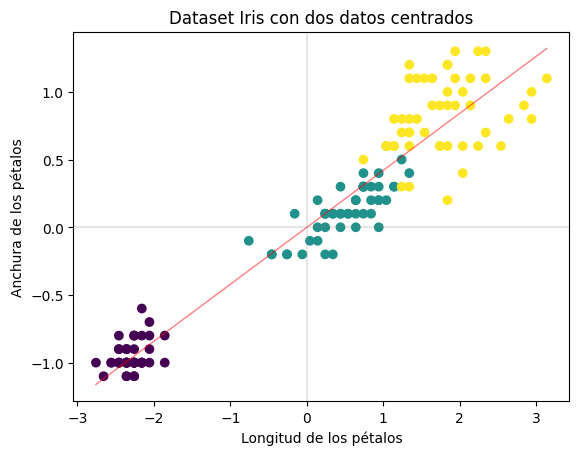

In [ ]:
# REPRESENTAMOS LOS DATOS

# Representamos los datos
plt.scatter(x1_centered, x2_centered, c=y_iris, cmap='viridis')

plt.xlabel('Longitud de los pétalos')
plt.ylabel('Anchura de los pétalos')
plt.title('Dataset Iris con dos datos centrados')


# Dibujamos la recta correspondiente primera componente principal
# eligiendo los puntos máximos y mínimos de la coordenada 1

min_x = np.min(___)
max_x = np.max(___)

# Calculamos las coordenadas y de los puntos anteriores:
min_x_y =  ___
max_x_y = ___

# Dibujamos la línea correspondiente a la primera componente principal
plt.plot([min_x, max_x], [min_x_y, max_x_y], color='r', label='Primera PC', linewidth=1, alpha =0.5)


# Establecemos líneas de eje en gris
plt.axhline(0, color='grey',alpha=0.2)  # Línea horizontal en y=0
plt.axvline(0, color='grey',alpha=0.2)  # Línea vertical en x=0

plt.show()


## Proyección sobre la primera componente principal


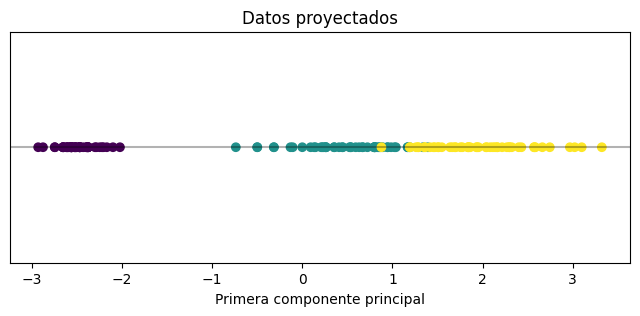

In [ ]:
# Proyectamos los datos sobre la primera componente principal
X_pca1 = X_centered @ V[:, 0]

# Representamos los datos proyectados
plt.figure(figsize=(8, 3))
plt.scatter(___, np.___(___), c=y_iris, cmap='viridis' )
plt.xlabel('Primera componente principal')

#eliminamos el eje y del gráfico
plt.gca().axes.get_yaxis().set_visible(False)

#representamos una linea horizontal en el eje x
plt.axhline(y=0, color='k', alpha=0.3)

plt.title('Datos proyectados')
plt.show()

## Comparamos las varianzas en las dos bases

In [ ]:
#Comparamos las varianzas en X

x1 = X_centered[___]
var_x1 = ___
print("La varianza a lo largo del eje de mayor varianza en la base original tenía un valor de: %.2f" % var_x1)

x2 = X_centered[___]
var_x2 = ___
print("La varianza a lo largo del eje de menor varianza en la base original tenía un valor de: %.2f" % var_x2)

print("La suma de las varianzas a lo largo de los dos ejes originales es : %.2f" % (var_x1 + var_x2))

La varianza a lo largo del eje de mayor varianza en la base original tenía un valor de: 3.12
La varianza a lo largo del eje de menor varianza en la base original tenía un valor de: 0.58
La suma de las varianzas a lo largo de los dos ejes originales es : 3.70


In [ ]:
#Comparamos las varianzas en Z
Z = X_centered @ ___
z1 = ___
var_z1 = np.var(___,ddof=1)
print("La varianza a lo largo del eje de mayor varianza en la nueva base tiene un valor de: %.2f" % var_z1)

Z = X_centered @ ___
z2 = ___
var_z2 = np.var(___,ddof=1)
print("La varianza a lo largo del eje de mayor varianza en la nueva base tiene un valor de: %.2f" % var_z2)

print("La suma de las varianzas a lo largo de los dos ejes originales es : %.2f" % (var_z1 + var_z2))

La varianza a lo largo del eje de mayor varianza en la nueva base tiene un valor de: 3.66
La varianza a lo largo del eje de mayor varianza en la nueva base tiene un valor de: 0.04
La suma de las varianzas a lo largo de los dos ejes originales es : 3.70


# PCA UTILIZANDO LIBRERÍAS

In [ ]:
from sklearn.decomposition import PCA


# Crear el objeto PCA para 2 componentes
pca = PCA(n_components=2)
X_pca = pca.___(X_iris)

# El método explained_variance_ nos da la varianza de cada componente, tal como la
# acabamos de calcular

print("Varianza explicada por cada componente: ", pca.___)

Varianza explicada por cada componente:  [3.66123805 0.03604607]


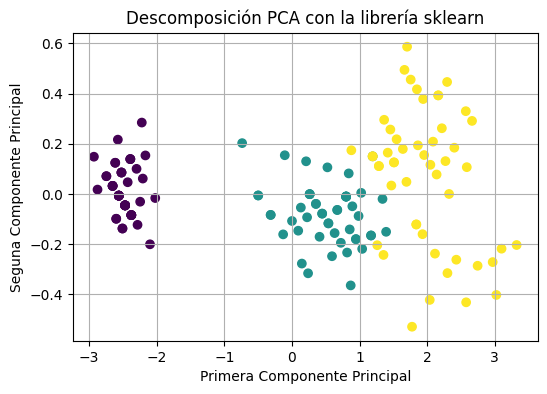

In [ ]:
# Representamos los datos
plt.figure(figsize=(6, 4))

#Incluir las etiquetas de las clases
plt.scatter(X_pca[___], X_pca[___], c=y_iris, cmap='viridis')
plt.xlabel('Primera Componente Principal')
plt.ylabel('Seguna Componente Principal')
plt.title('Descomposición PCA con la librería sklearn')
plt.grid(True)
plt.show()
